## Telco Customer Churn – Customer Churn Prediction with Interpretability

## Problem
A telecom company is losing about 1 in 4 customers (26.5% churn). Retention
teams can't contact everyone, and a list of "at-risk" customers isn't enough:
to act, they need to know **why** each customer is likely to leave — so they
can offer the right incentive (a longer contract, tech support, a discount).

## Goal
Build a model that:
1. Identifies customers at high risk of churning, evaluated with metrics suited
   to imbalanced data (PR-AUC, recall, precision) rather than accuracy.
2. Explains what drives churn, through the EDA, the Logistic Regression
     baseline and readable Decision Tree rules.
3. Uses a decision threshold chosen by business cost, not the default 0.5.

### Description
- **Dataset:** [Telco Customer Churn (IBM sample, via Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
  — 7,043 customers, 20 features (demographics, account info, subscribed
  services) and a binary target `Churn`.
- **Models:** Logistic Regression (interpretable baseline), Decision Tree
  (human-readable rules) and XGBoost (high performance, tuned with
  `RandomizedSearchCV`).
- **Validation:** stratified 80/20 train/test split; 5-fold stratified
  cross-validation on the training set; the test set is used only once.
- **Interpretability:** odds ratios (Logistic Regression), decision rules
  (Decision Tree).
- **Output:** a saved scikit-learn pipeline (preprocessing + model) and
  threshold, ready to be served through an API.


### 1. Business Question

**Which customers are most likely to churn, and what factors explain their risk,
so the retention team can decide whom to contact and what to offer?**

In [1]:
   # Business cost assumptions (illustrative, used in Step 12)
   # OFFER_COST = 50              # cost of a retention action (discount, call), in $
   # REVENUE_MONTHS = 12          # months of revenue lost when a customer churns
   # OFFER_SUCCESS_RATE = 0.30    # share of contacted churners who stay thanks to the offer

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
RANDOM_STATE = 42


### 2. Load data / clean up

In [4]:
# import and upload the file
# Local setup: work from the project folder (adjust if you clone this repo elsewhere)

base_path = Path(r'C:\Projects\AI Projects\3. Abandono de clientes con interpretabilidad\data')
df = pd.read_csv(base_path / 'WA_Fn-UseC_-Telco-Customer-Churn.csv')

display(df.head(5).style.hide(axis='index'))


customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850000,29.85,No
5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950000,1889.5,No
3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850000,108.15,Yes
7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300000,1840.75,No
9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700000,151.65,Yes


In [5]:
# data inspection

df.info()
print("\nDuplicated customerID:", df["customerID"].duplicated().sum())
print("\nTarget distribution:")
print(df["Churn"].value_counts(normalize=True).round(3))

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
# TotalCharges is stored as text: some values are blank strings

total_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Non-numeric TotalCharges:", total_numeric.isna().sum())
df.loc[total_numeric.isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Non-numeric TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [9]:
# Clean up
df_clean = df.copy()

# TotalCharges: text -> numeric; new customers (tenure = 0) have no charges yet
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce").fillna(0)

# customerID is an identifier, not a feature
df_clean = df_clean.drop(columns="customerID")

# Target: Yes/No -> 1/0
df_clean["Churn"] = df_clean["Churn"].map({"Yes": 1, "No": 0})

# SeniorCitizen is coded 0/1 but is categorical, like the other Yes/No columns
df_clean["SeniorCitizen"] = df_clean["SeniorCitizen"].map({1: "Yes", 0: "No"})

df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   str    
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [10]:
# Verify clean up

assert df_clean.isna().sum().sum() == 0, "There are still missing values"
assert df_clean["Churn"].isin([0, 1]).all()

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df_clean.columns if c not in num_cols + ["Churn"]]
print(f"{len(num_cols)} numeric: {num_cols}")
print(f"{len(cat_cols)} categorical: {cat_cols}")

3 numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']
16 categorical: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### 3. EDA (Exploratory Data Analysis)

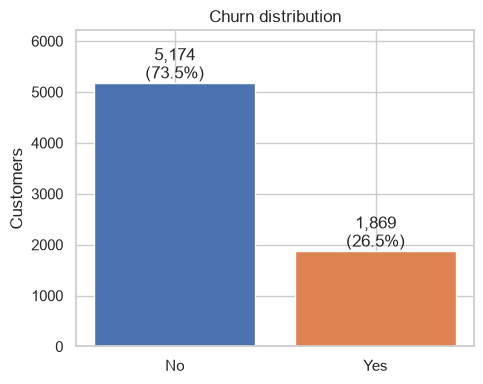

In [11]:
# Analysis of classes

sns.set_theme(style="whitegrid")
CHURN_RATE = df_clean["Churn"].mean()

fig, ax = plt.subplots(figsize=(5, 4))
counts = df_clean["Churn"].map({0: "No", 1: "Yes"}).value_counts()
ax.bar(counts.index, counts.values, color=["#4C72B0", "#DD8452"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v/len(df_clean):.1%})", ha="center", va="bottom")
    
ax.set_title("Churn distribution")
ax.set_ylabel("Customers")
ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.show()

- **Imbalanced target:** 26.5% churn. A model predicting "no churn" for everyone
  would reach 73.5% accuracy, so accuracy is not a useful metric here.

In [12]:
tenure_group = pd.cut(df_clean["tenure"], bins=[-1, 12, 24, 48, 72],
                      labels=["0-12", "13-24", "25-48", "49-72"])

# Table 1: churned customers (Churn = 1)
churners = pd.crosstab(tenure_group, df_clean["Contract"],
                       values=df_clean["Churn"], aggfunc="sum")

# Table 2: share of all churners in each cell (%)
churners_share = churners / churners.to_numpy().sum() * 100

# Table 3: churn rate within each cell (%)
churn_rate = pd.crosstab(tenure_group, df_clean["Contract"],
                         values=df_clean["Churn"], aggfunc="mean") * 100

# Table 4: total customers in each cell
client_count = pd.crosstab(tenure_group, df_clean["Contract"])

summary = pd.concat(
    {
        "Churned customers": churners,
        "% of all churners": churners_share.round(1),
        "Churn rate (%)": churn_rate.round(1),
        "Customer count": client_count,
    },
    axis=1,
)
summary.index.name = "tenure"
display(summary)

Churned customers                   % of all churners           \
Contract    Month-to-month One year Two year    Month-to-month One year   
tenure                                                                    
0-12                  1024       13        0              54.8      0.7   
13-24                  278       16        0              14.9      0.9   
25-48                  264       55        6              14.1      2.9   
49-72                   89       82       42               4.8      4.4   

                  Churn rate (%)                   Customer count           \
Contract Two year Month-to-month One year Two year Month-to-month One year   
tenure                                                                       
0-12          0.0           51.4     10.5      0.0           1994      124   
13-24         0.0           37.7      8.1      0.0            737      197   
25-48         0.3           32.9     10.6      2.2            802      518   
49-72         2.2           26.0     12.9      3.3            342      634   

                   
Contract Two year  
tenure             
0-12           68  
13-24          90  
25-48         274  
49-72        1263

### Tenure × Contract: where churners are

The table combines four views of each tenure × contract group: how many customers
churned, what share of all churners they represent, their churn rate, and the
group size.

- **Churn is concentrated, not spread out:** 88.6% of all churners are on
  month-to-month contracts, and 54.8% are month-to-month customers in their
  first year (1,024 of 1,869).
- **That group is both large and high-risk:** almost 2,000 customers, half of whom
  leave. It's the main target for retention.
- **Risk falls with tenure but stays high on month-to-month:** from 51.4% in the
  first year to 26.0% after 4+ years.
- **Long contracts protect:** one-year churn stays around 8–13%, and two-year
  churn is near zero, accounting for only 2.5% of all churners.
- **Business takeaway:** moving new month-to-month customers to longer contracts
  early, within their first 12 months, would address the largest pool of churn.

In [14]:
# Reusable summary: churned customers, share of all churners, churn rate and group size
def churn_summary(data, col):
    g = data.groupby(col)["Churn"]
    return pd.DataFrame({
        "Churned customers": g.sum(),
        "% of all churners": g.sum() / data["Churn"].sum() * 100,
        "Churn rate (%)": g.mean() * 100,
        "Customer count": g.size(),
    }).round(1)

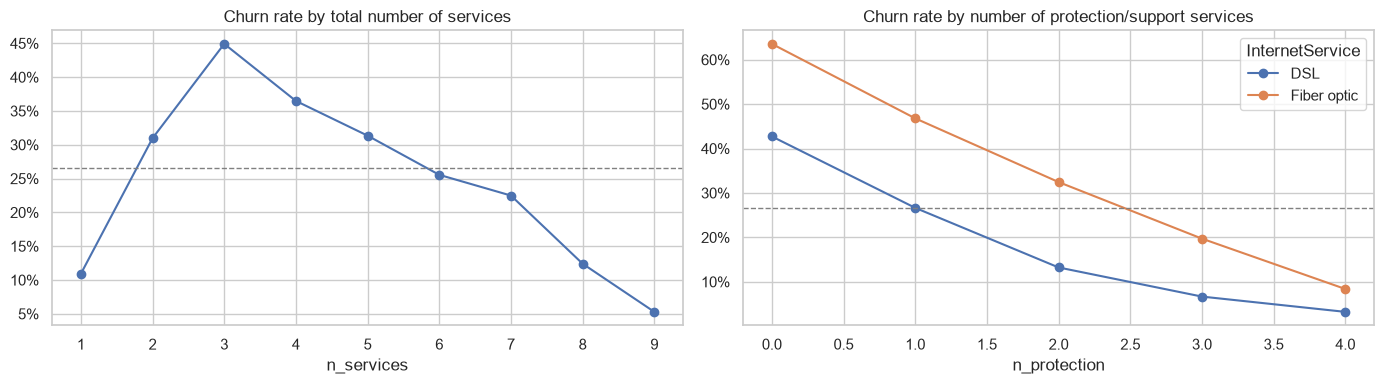

,Churned customers,% of all churners,Churn rate (%),Customer count
n_services,,,,
1,138,7.4,10.9,1264
2,266,14.2,31.0,859
3,380,20.3,44.9,846
4,352,18.8,36.5,965
5,289,15.5,31.3,922
6,232,12.4,25.6,908
7,152,8.1,22.5,676
8,49,2.6,12.4,395
9,11,0.6,5.3,208


,Churned customers,% of all churners,Churn rate (%),Customer count
n_protection,,,,
0,718,40.9,56.7,1267
1,570,32.5,38.9,1467
2,326,18.6,23.8,1372
3,117,6.7,12.4,941
4,25,1.4,5.3,470


In [15]:
# Amount of service by customer
# Number of services by customer

service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
protection_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]

eda = df_clean.copy()
eda["n_services"] = (eda[service_cols] == "Yes").sum(axis=1) + (eda["InternetService"] != "No")
eda["n_protection"] = (eda[protection_cols] == "Yes").sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
eda.groupby("n_services")["Churn"].mean().plot(marker="o", ax=axes[0])
axes[0].set_title("Churn rate by total number of services")
(pd.crosstab(eda["n_protection"], eda["InternetService"], values=eda["Churn"], aggfunc="mean")
   [["DSL", "Fiber optic"]].plot(marker="o", ax=axes[1]))
axes[1].set_title("Churn rate by number of protection/support services")
for ax in axes:
    ax.axhline(CHURN_RATE, color="gray", linestyle="--", linewidth=1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.tight_layout()
plt.show()

# Churned customers by number of services
display(churn_summary(eda, "n_services"))

# Protection/support services only apply to internet customers
internet = eda[eda["InternetService"] != "No"]
display(churn_summary(internet, "n_protection"))

### Services: findings

- **Total number of services is not linear.** Churn rate peaks at 3 services (44.9%)
  and falls to 5.3% at 9. Customers with a single service rarely leave (10.9%)
  because most of them have phone only, no internet.
- **Most churners have 2–5 services** (68.8% of them). Customers with 8–9 services
  rarely leave (60 churners in total).
- **Protection/support services are the clearer signal.** Among internet customers,
  churn drops steadily as protection services increase, for both DSL and fiber:
  from 56.7% with none to 5.3% with all four.
- **73.4% of internet churners had 0 or 1 protection service** (1,288 of 1,756),
  while only 25 churners had all four.
- **Fiber churns more than DSL at every level**, but follows the same pattern.
  Protection services matter more than the internet type itself.
- `n_protection` is a candidate engineered feature for Step 5.

In [17]:
eda["family"] = np.select(
    [(eda["Partner"] == "Yes") & (eda["Dependents"] == "Yes"),
     (eda["Partner"] == "Yes") & (eda["Dependents"] == "No"),
     (eda["Partner"] == "No") & (eda["Dependents"] == "Yes")],
    ["Partner + dependents", "Partner only", "Dependents only"],
    default="Single",
)

display(churn_summary(eda, "family").sort_values("Churned customers", ascending=False))

# Contract mix among churners only (row %)
churned = eda[eda["Churn"] == 1]
display((pd.crosstab(churned["family"], churned["Contract"], normalize="index") * 100).round(1))

,Churned customers,% of all churners,Churn rate (%),Customer count
family,,,,
Single,1123,60.1,34.2,3280
Partner only,420,22.5,25.4,1653
Partner + dependents,249,13.3,14.2,1749
Dependents only,77,4.1,21.3,361


Contract,Month-to-month,One year,Two year
family,,,
Dependents only,88.3,9.1,2.6
Partner + dependents,76.7,16.9,6.4
Partner only,83.1,13.3,3.6
Single,93.2,5.4,1.3


### Family profile: findings (churned customers)

- **60.1% of churners are single** (1,123 of 1,869), with a 34.2% churn rate.
  Customers with a partner and dependents are the most loyal (14.2%).
- **Almost all single churners were on month-to-month contracts (93.2%).**
  Family profile and contract type reinforce each other.

In [18]:
# Fiber customers
fiber = eda[eda["InternetService"] == "Fiber optic"]
summary = churn_summary(fiber, "n_protection")
summary["Median monthly charge"] = fiber.groupby("n_protection")["MonthlyCharges"].median()
display(summary)

,Churned customers,% of all churners,Churn rate (%),Customer count,Median monthly charge
n_protection,,,,,
0,539,41.6,63.6,848,78.950
1,416,32.1,46.8,889,89.600
2,244,18.8,32.4,752,98.550
3,82,6.3,19.7,416,106.025
4,16,1.2,8.4,191,113.650


### Fiber optic paradox

Fiber customers pay more and churn more (41.9%, and 69.4% of all churners), which
suggests price is the problem. But within fiber, customers who pay *more* churn
*less*: higher bills come from protection services, and those services retain.
The risk is **fiber without add-ons**: 63.6% churn with no protection services
vs 8.4% with all four. The data can't tell why (price/value perception, service
quality, competition), but it identifies the target group.

### EDA summary

**Who churns:** 1,869 customers (26.5%). Churn is concentrated, not spread out:
- **88.6%** of churners are on month-to-month contracts.
- **54.8%** are month-to-month customers in their **first year**.
- **69.4%** have fiber optic internet, mostly without protection services.
- **60.1%** are single (no partner, no dependents).
- **57.3%** paid by electronic check.

**The fiber optic paradox:** fiber is the most expensive internet service
(median $91.68 vs $56.15 for DSL) and concentrates 69.4% of churners; churners
also pay more per month overall (median $79.65 vs $64.43). But within fiber,
customers who pay *more* churn *less*: higher bills come from protection
services, which retain. The highest risk is **fiber without add-ons** (63.6%
churn): customers paying a high price for internet alone, which points to
a price/value perception problem.

**Main risk drivers:** contract type, tenure, lack of protection/support services
(online security, tech support), fiber optic without add-ons, and electronic check payment.

**No signal:** gender and phone service.

**Implications for modeling:**
- Imbalanced target → evaluate with PR-AUC, recall and precision, not accuracy.
- Strong interactions (contract × tenure × services) → tree-based models should
  outperform Logistic Regression.
- Redundant features (`TotalCharges`, `PhoneService`, "No internet service" levels)
  → handle them for Logistic Regression later.
- Candidate engineered feature: `n_protection`.

### 4. Train/Test Split and Cross-Validation

1. **Holdout test set (20%)**: the first fold of a stratified 5-fold split.
   It is kept aside until the final evaluation and used only once.
2. **5-fold stratified cross-validation on the training set (80%)**: used to
   compare models (Step 9) and tune XGBoost (Step 10).

Stratification keeps the 26.5% churn rate in every split.

In [19]:
from sklearn.model_selection import StratifiedKFold

X = df_clean.drop(columns="Churn")
y = df_clean["Churn"]

# 1. Holdout: first fold of a stratified 5-fold split -> 80% train / 20% test
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(outer.split(X, y))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Train: {X_train.shape}  churn rate: {y_train.mean():.3f}")
print(f"Test:  {X_test.shape}  churn rate: {y_test.mean():.3f}")

# 2. Cross-validation folds on the training set 
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

folds = [{"fold": i, "train_size": len(tr), "val_size": len(va),
          "val_churn_rate": round(y_train.iloc[va].mean(), 3)}
         for i, (tr, va) in enumerate(cv.split(X_train, y_train), start=1)]
pd.DataFrame(folds)

Train: (5634, 19)  churn rate: 0.265
Test:  (1409, 19)  churn rate: 0.265


,fold,train_size,val_size,val_churn_rate
0,1,4507,1127,0.265
1,2,4507,1127,0.265
2,3,4507,1127,0.265
3,4,4507,1127,0.265
4,5,4508,1126,0.266


### 5. Preprocessing Pipeline

All preprocessing lives inside scikit-learn pipelines, so it is learned **only
from the training data** (no leakage) and can be saved together with the model.

1. **Feature engineering** (shared):
   - "No internet service" → "No" in the 6 add-on columns, and "No phone service"
     → "No" in `MultipleLines`. That information is already in `InternetService`
     and `PhoneService`, so the duplicated levels are removed.
   - `n_protection`: number of protection/support services (0–4), from the EDA.
2. **Two preprocessors**, because the models have different needs:
   - **Linear (Logistic Regression):** drops redundant features, scales numeric
     features and one-hot encodes with a reference category (`drop="first"`), so
     each coefficient reads as "vs. the reference".
   - **Tree (Decision Tree, XGBoost):** keeps every feature, with no scaling
     (trees don't need it) and one dummy per category.

In [20]:
# Feature engineering
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

from features import (engineer_features, INTERNET_ADDONS, PROTECTION_COLS,
                      NUM_FEATURES, CAT_FEATURES)

In [21]:
# Preprocesing
def make_linear_preprocessor(drop_cols):
    """Scaled numerics + one-hot with reference category, without drop_cols."""
    return Pipeline([
        ("features", FunctionTransformer(engineer_features)),
        ("encode", ColumnTransformer([
            ("num", StandardScaler(), [c for c in NUM_FEATURES if c not in drop_cols]),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
                    [c for c in CAT_FEATURES if c not in drop_cols]),
        ], verbose_feature_names_out=False)),
    ])

# Redundant features removed for Logistic Regression (see VIF check below)
LINEAR_DROP = ["TotalCharges", "PhoneService", "n_protection", "MonthlyCharges"]
preprocess_linear = make_linear_preprocessor(LINEAR_DROP)

preprocess_tree = Pipeline([
    ("features", FunctionTransformer(engineer_features)),
    ("encode", ColumnTransformer([
        ("num", "passthrough", NUM_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
    ], verbose_feature_names_out=False)),
])

for name, prep in [("Linear", preprocess_linear), ("Tree", preprocess_tree)]:
    Xt = prep.fit_transform(X_train)
    print(f"{name}: {Xt.shape[1]} features")
    print(list(prep.named_steps["encode"].get_feature_names_out()), "\n")

Linear: 20 features
['tenure', 'gender_Male', 'SeniorCitizen_Yes', 'Partner_Yes', 'Dependents_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'] 

Tree: 40 features
['tenure', 'MonthlyCharges', 'TotalCharges', 'n_protection', 'gender_Female', 'gender_Male', 'SeniorCitizen_No', 'SeniorCitizen_Yes', 'Partner_No', 'Partner_Yes', 'Dependents_No', 'Dependents_Yes', 'PhoneService_No', 'PhoneService_Yes', 'MultipleLines_No', 'MultipleLines_Yes', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No', 'OnlineSecurity_Yes', 'OnlineBackup_No', 'OnlineBackup_Yes', 'DeviceProtection_No', 'DeviceProtection_Yes', 'TechSupport_No', 'TechSu

In [22]:
# Verify multicolineality (VIF)
from sklearn.linear_model import LinearRegression

def vif_table(prep):
    """Variance Inflation Factor of each feature produced by a linear preprocessor."""
    Xt = pd.DataFrame(prep.fit_transform(X_train),
                      columns=prep.named_steps["encode"].get_feature_names_out())
    vif = {}
    for col in Xt.columns:
        others = Xt.drop(columns=col)
        r2 = LinearRegression().fit(others, Xt[col]).score(others, Xt[col])
        vif[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(vif, name="VIF").sort_values(ascending=False).round(1)

before = vif_table(make_linear_preprocessor(["TotalCharges", "PhoneService"]))
after = vif_table(preprocess_linear)
display(pd.concat({"VIF before": before.head(8), "VIF after": after.head(8)}, axis=1))

,VIF before,VIF after
n_protection,inf,NaN
TechSupport_Yes,inf,NaN
OnlineSecurity_Yes,inf,NaN
OnlineBackup_Yes,inf,NaN
DeviceProtection_Yes,inf,NaN
MonthlyCharges,34.0,NaN
InternetService_Fiber optic,10.2,1.7
InternetService_No,4.9,2.5
tenure,NaN,2.8
Contract_Two year,NaN,2.6


### Preprocessing: decisions

**Variance Inflation Factor (VIF)** measures how much a feature is explained by the
others (VIF > 10 is a common warning sign). Two problems appeared for Logistic Regression:

- **`n_protection` is an exact sum** of the 4 protection dummies (VIF = ∞). The model
  can't separate their effects. For Logistic Regression we keep the 4 individual
  services, which are more actionable; `n_protection` is used by the tree models only.
- **`MonthlyCharges` is ~97% explained by the services** a customer has (VIF ≈ 34):
  the bill is essentially the sum of the services. Keeping it would make the service
  coefficients unstable. Logistic Regression uses the services instead of the price.

After removing `TotalCharges`, `PhoneService`, `n_protection` and `MonthlyCharges`,
every VIF is below 3. **The tree models keep all 40 features**: trees are not
affected by collinearity.

### 6. Baseline Models

- **Dummy classifier:** always predicts "no churn". It sets the floor and shows
  why accuracy is misleading.
- **Logistic Regression:** the interpretable baseline. `class_weight="balanced"`
  gives more weight to churners (the minority class), so the model doesn't
  ignore them.

All models are evaluated with the same 5-fold cross-validation on the training set.

In [23]:
# Evaluation functions

from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, precision_score

SCORING = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": "f1",
    "accuracy": "accuracy",
}

cv_results = {}

def evaluate(name, model):
    """Cross-validate a pipeline on the training set and add it to the results table."""
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    cv_results[name] = {metric: scores[f"test_{metric}"].mean() for metric in SCORING}
    return pd.DataFrame(cv_results).T.round(3)

In [38]:
# Evaluate the models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

dummy = Pipeline([
    ("prep", preprocess_linear),
    ("model", DummyClassifier(strategy="most_frequent")),
])
evaluate("Dummy (always 'no churn')", dummy)

log_reg = Pipeline([
    ("prep", preprocess_linear),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000,
                                 random_state=RANDOM_STATE)),
])
evaluate("Logistic Regression", log_reg)

,roc_auc,pr_auc,recall,precision,f1,accuracy
Decision Tree,0.822,0.588,0.763,0.504,0.606,0.737
XGBoost (default),0.813,0.608,0.654,0.545,0.594,0.763
XGBoost (tuned),0.845,0.662,0.805,0.517,0.629,0.748
Dummy (always 'no churn'),0.500,0.265,0.000,0.000,0.000,0.735
Logistic Regression,0.839,0.645,0.788,0.513,0.621,0.745


### Baseline: findings

- **Accuracy is misleading:** the Dummy reaches 73.5% accuracy while detecting
  zero churners. Logistic Regression barely improves accuracy (74.5%), yet it is
  far more useful.
- **Logistic Regression detects 78.8% of churners** (recall), but about half of
  its alerts are false alarms (precision 51.3%). This trade-off comes from
  `class_weight="balanced"` and the default 0.5 threshold; Step 12 will tune it
  by business cost.
- **PR-AUC rises from 0.265 (random) to 0.645.** This is the main metric to beat
  with the tree models.

 #### Evaluation Metrics
- Recall: Of all customers who actually churned, how many did the model correctly identify?
- Precision: Of all customers the model predicted would churn, how many actually did?
- PR-AUC: Summarizes the trade-off between precision and recall across different decision thresholds. For a random classifier, the baseline is 0.265, which corresponds to the churn rate (26.5%).
 

### 7. Decision Tree

A shallow tree gives **human-readable rules** a retention team can act on directly.
Depth is a trade-off: deeper trees score slightly better but quickly become
unreadable. `min_samples_leaf=50` prevents rules based on very few customers.

In [25]:
# Selection of the max_depth (3-5)

from sklearn.tree import DecisionTreeClassifier, plot_tree

depth_rows = []
for depth in [3, 4, 5, 6]:
    tree = Pipeline([
        ("prep", preprocess_tree),
        ("model", DecisionTreeClassifier(max_depth=depth, class_weight="balanced",
                                         min_samples_leaf=50, random_state=RANDOM_STATE)),
    ])
    scores = cross_validate(tree, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    depth_rows.append({"max_depth": depth, **{m: scores[f"test_{m}"].mean() for m in SCORING}})

pd.DataFrame(depth_rows).round(3)

,max_depth,roc_auc,pr_auc,recall,precision,f1,accuracy
0,3,0.812,0.552,0.784,0.509,0.617,0.742
1,4,0.822,0.588,0.763,0.504,0.606,0.737
2,5,0.823,0.597,0.799,0.497,0.612,0.731
3,6,0.823,0.611,0.783,0.506,0.615,0.739


In [26]:
# The tree selected

TREE_DEPTH = 4   # 16 leaves: still readable; deeper trees gain little PR-AUC

decision_tree = Pipeline([
    ("prep", preprocess_tree),
    ("model", DecisionTreeClassifier(max_depth=TREE_DEPTH, class_weight="balanced",
                                     min_samples_leaf=50, random_state=RANDOM_STATE)),
])
evaluate("Decision Tree", decision_tree)

,roc_auc,pr_auc,recall,precision,f1,accuracy
Decision Tree,0.822,0.588,0.763,0.504,0.606,0.737


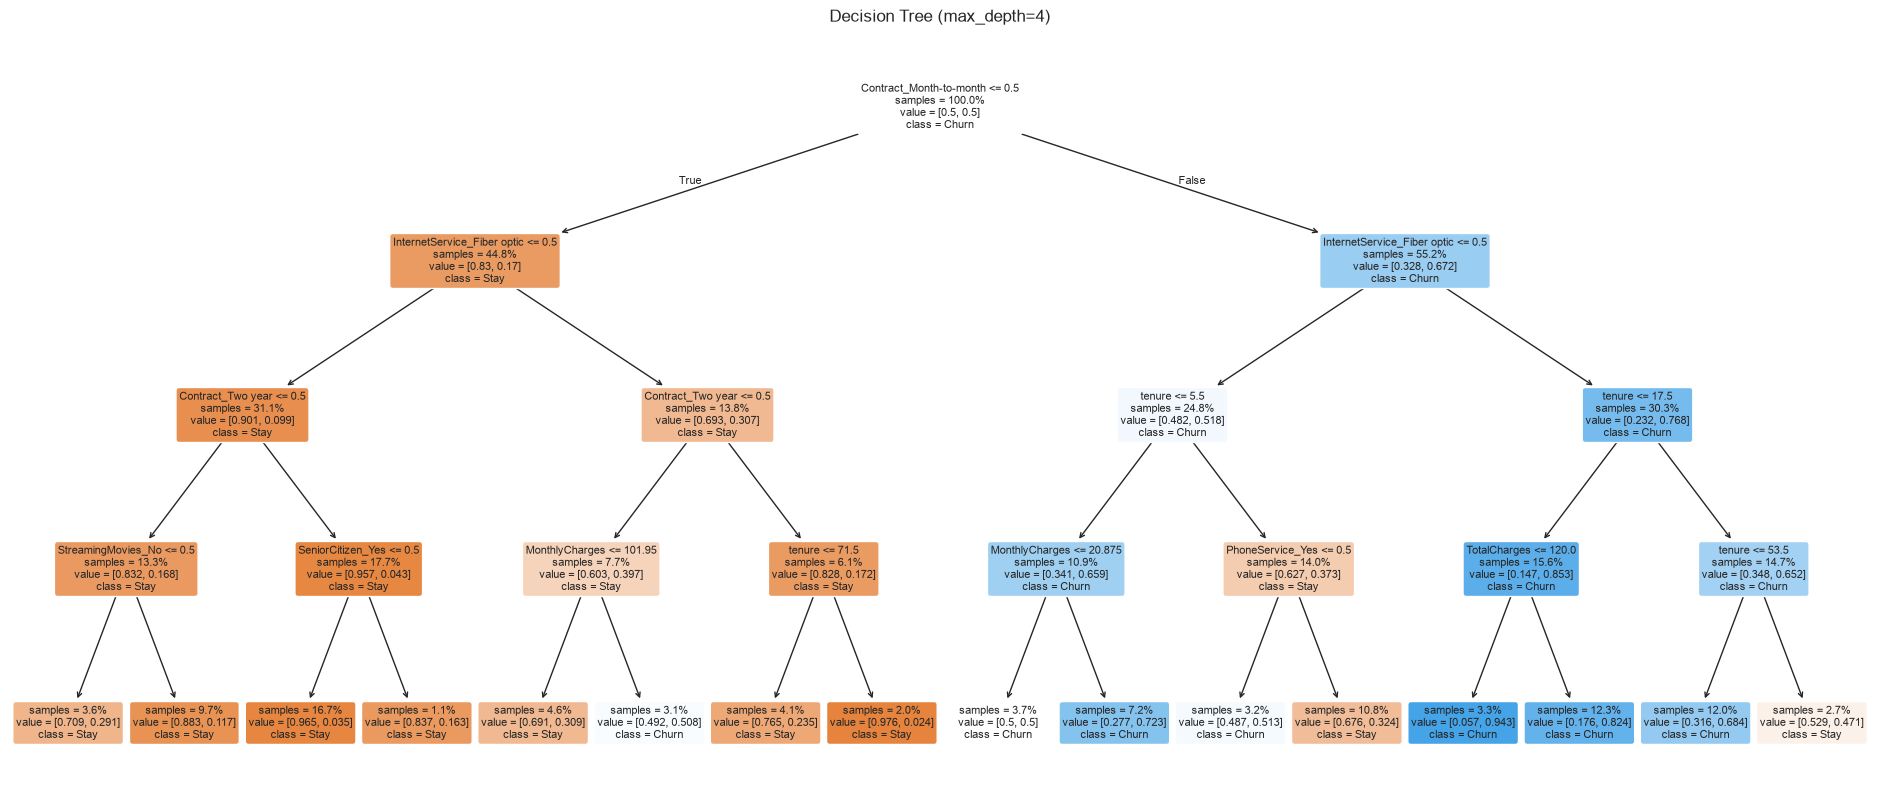

In [27]:
# Tree graphic

decision_tree.fit(X_train, y_train)
feature_names = decision_tree.named_steps["prep"].named_steps["encode"].get_feature_names_out()

fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(decision_tree.named_steps["model"], feature_names=feature_names,
          class_names=["Stay", "Churn"], filled=True, rounded=True,
          proportion=True, impurity=False, fontsize=8, ax=ax)
ax.set_title(f"Decision Tree (max_depth={TREE_DEPTH})")
plt.show()

In [28]:
# Business rules

def tree_rules(pipeline, X, y):
    """One row per leaf: its rule, customers, churners and churn rate (real counts)."""
    model = pipeline.named_steps["model"]
    prep = pipeline.named_steps["prep"]
    names = prep.named_steps["encode"].get_feature_names_out()
    t = model.tree_
    paths = {}

    def walk(node, conditions):
        if t.children_left[node] == -1:          # leaf
            paths[node] = " AND ".join(conditions)
            return
        f, thr = names[t.feature[node]], t.threshold[node]
        if f in NUM_FEATURES:
            left, right = f"{f} <= {thr:.1f}", f"{f} > {thr:.1f}"
        else:                                    # one-hot dummy, e.g. "Contract_Two year"
            col, value = f.split("_", 1)
            left, right = f"{col} is not {value}", f"{col} is {value}"
        walk(t.children_left[node], conditions + [left])
        walk(t.children_right[node], conditions + [right])

    walk(0, [])
    leaves = model.apply(prep.transform(X))
    out = (pd.DataFrame({"leaf": leaves, "Churn": y.to_numpy()})
             .groupby("leaf")["Churn"]
             .agg(customers="size", churners="sum", churn_rate="mean"))
    out["% of all churners"] = out["churners"] / out["churners"].sum() * 100
    out["rule"] = out.index.map(paths)
    return out.sort_values("churners", ascending=False).round(3).reset_index(drop=True)

pd.set_option("display.max_colwidth", None)
tree_rules(decision_tree, X_train, y_train)

,customers,churners,churn_rate,% of all churners,rule
0,693,436,0.629,29.164,Contract is Month-to-month AND InternetService is Fiber optic AND tenure <= 17.5 AND TotalCharges > 120.0
1,676,297,0.439,19.866,Contract is Month-to-month AND InternetService is Fiber optic AND tenure > 17.5 AND tenure <= 53.5
2,406,197,0.485,13.177,Contract is Month-to-month AND InternetService is not Fiber optic AND tenure <= 5.5 AND MonthlyCharges > 20.9
3,187,160,0.856,10.702,Contract is Month-to-month AND InternetService is Fiber optic AND tenure <= 17.5 AND TotalCharges <= 120.0
4,609,90,0.148,6.020,Contract is Month-to-month AND InternetService is not Fiber optic AND tenure > 5.5 AND PhoneService is Yes
5,207,55,0.266,3.679,Contract is Month-to-month AND InternetService is not Fiber optic AND tenure <= 5.5 AND MonthlyCharges <= 20.9
6,178,49,0.275,3.278,Contract is Month-to-month AND InternetService is not Fiber optic AND tenure > 5.5 AND PhoneService is not Yes
7,173,47,0.272,3.144,Contract is not Month-to-month AND InternetService is Fiber optic AND Contract is not Two year AND MonthlyCharges > 102.0
8,152,37,0.243,2.475,Contract is Month-to-month AND InternetService is Fiber optic AND tenure > 17.5 AND tenure > 53.5
9,259,36,0.139,2.408,Contract is not Month-to-month AND InternetService is Fiber optic AND Contract is not Two year AND MonthlyCharges <= 102.0


### Decision Tree: findings

- **Performance:** PR-AUC 0.588, below Logistic Regression (0.645). A depth-4 tree
  is too simple to beat it; its value here is readability, not accuracy.
- **The tree confirms the EDA without being told:** the first split is contract
  type, then fiber optic, then tenure.
- **4 rules capture 72.9% of all churners in the training set** (1,090 of 1,495),
  all of them month-to-month customers:
  1. Fiber, first ~1.5 years: 436 churners (62.9% churn rate).
  2. Fiber, 1.5 to 4.5 years: 297 churners (43.9%).
  3. No fiber, first ~6 months, paying more than the basic plan: 197 churners (48.5%).
  4. Fiber, brand new (total charges ≤ $120, about 1–2 months): **85.6% churn**.
     These customers leave almost immediately, which points to onboarding or
     first-bill problems.
- **Business takeaway:** "month-to-month + fiber + first year" is a simple,
  actionable rule the retention team could apply even without a model.

### 8. XGBoost (default parameters)

XGBoost builds hundreds of small trees sequentially, each one correcting the
errors of the previous ones. It captures interactions (contract × tenure ×
services) that Logistic Regression can't.

- `scale_pos_weight` = non-churners / churners (≈ 2.77) plays the same role as
  `class_weight="balanced"`.
- We first train it with default parameters, to measure how much tuning
  (Step 10) improves it.

In [30]:
# Evaluate the model

from xgboost import XGBClassifier

SCALE_POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {SCALE_POS_WEIGHT:.2f}")

xgb_default = Pipeline([
    ("prep", preprocess_tree),
    ("model", XGBClassifier(scale_pos_weight=SCALE_POS_WEIGHT, eval_metric="logloss",
                            random_state=RANDOM_STATE, n_jobs=-1)),
])
evaluate("XGBoost (default)", xgb_default)

scale_pos_weight = 2.77


,roc_auc,pr_auc,recall,precision,f1,accuracy
Decision Tree,0.822,0.588,0.763,0.504,0.606,0.737
XGBoost (default),0.813,0.608,0.654,0.545,0.594,0.763


In [31]:
# Overfitting Check (Training vs. Validation)

scores = cross_validate(xgb_default, X_train, y_train, cv=cv, scoring=SCORING,
                        return_train_score=True, n_jobs=-1)
pd.DataFrame({
    "train": {m: scores[f"train_{m}"].mean() for m in SCORING},
    "validation": {m: scores[f"test_{m}"].mean() for m in SCORING},
}).round(3)

,train,validation
roc_auc,0.994,0.813
pr_auc,0.979,0.608
recall,0.997,0.654
precision,0.823,0.545
f1,0.902,0.594
accuracy,0.942,0.763


### XGBoost (default): findings

- **It does not beat Logistic Regression** (PR-AUC 0.608 vs 0.645), and even
  falls below it on ROC-AUC (0.813 vs 0.839).
- **The reason is overfitting:** PR-AUC is 0.979 on the training folds but 0.608
  on validation. The default settings (300 trees of depth 6, no regularization in
  practice) let the model memorize the training customers instead of learning
  general patterns.
- **This is a common result on small tabular datasets** (5,634 training rows):
  a powerful model without tuning can lose to a simple linear one.
- **Next step:** tune XGBoost (Step 10) with shallower trees, a lower learning
  rate and regularization, to close the gap between train and validation.

### 9. Model Comparison (cross-validation on the training set)

All models share the same 5 folds and metrics. They are ranked by **PR-AUC**, the
main metric: it focuses on the churn class and doesn't depend on the 0.5 threshold.

In [32]:
# Comparative Table
comparison = pd.DataFrame(cv_results).T.sort_values("pr_auc", ascending=False)
comparison.round(3)

,roc_auc,pr_auc,recall,precision,f1,accuracy
XGBoost (default),0.813,0.608,0.654,0.545,0.594,0.763
Decision Tree,0.822,0.588,0.763,0.504,0.606,0.737


### Model comparison: findings

- **Logistic Regression leads** on PR-AUC (0.645), ROC-AUC (0.839), recall and F1.
  The EDA already explained why: churn is driven by a few strong, mostly
  monotonic factors (contract, tenure, services), which a linear model captures well.
- **Default XGBoost is second on PR-AUC (0.608)** but overfits heavily
  (0.979 on train). It has the best precision and accuracy, but misses more
  churners (recall 0.654).
- **The Decision Tree (depth 4)** trades performance for readable rules.
- **All models are far above the Dummy**, which confirms they learned real patterns.
- **Open question for Step 10:** can tuning make XGBoost beat Logistic Regression?
  If the gain is small, the simpler and more interpretable model may be the
  better business choice.

### 10. XGBoost Hyperparameter Tuning

`RandomizedSearchCV` tests 50 random combinations of hyperparameters with the
same 5-fold cross-validation, and keeps the one with the best PR-AUC.
The search space focuses on reducing overfitting:

| Hyperparameter | What it controls | Range |
|---|---|---|
| `n_estimators` | number of trees | 100–600 |
| `max_depth` | depth of each tree (lower = simpler) | 2–6 |
| `learning_rate` | how much each tree contributes (lower = more cautious) | 0.01–0.3 |
| `subsample` | share of customers used per tree | 0.6–1.0 |
| `colsample_bytree` | share of features used per tree | 0.5–1.0 |
| `min_child_weight` | minimum data needed to create a split | 1–20 |
| `gamma` | minimum improvement needed to create a split | 0–5 |
| `reg_lambda` | L2 regularization (penalizes large weights) | 0.1–20 |

In [33]:
# Random search to optimized hyperparameters

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

param_distributions = {
    "model__n_estimators": randint(100, 600),
    "model__max_depth": randint(2, 7),
    "model__learning_rate": loguniform(0.01, 0.3),
    "model__subsample": uniform(0.6, 0.4),          # 0.6 to 1.0
    "model__colsample_bytree": uniform(0.5, 0.5),   # 0.5 to 1.0
    "model__min_child_weight": randint(1, 20),
    "model__gamma": uniform(0, 5),
    "model__reg_lambda": loguniform(0.1, 20),
}

search = RandomizedSearchCV(
    xgb_default, param_distributions, n_iter=50, scoring="average_precision",
    cv=cv, n_jobs=-1, random_state=RANDOM_STATE, return_train_score=True,
)
search.fit(X_train, y_train)

best = pd.DataFrame(search.cv_results_).loc[search.best_index_]
print(f"Best PR-AUC (validation): {best['mean_test_score']:.3f}")
print(f"Train PR-AUC:             {best['mean_train_score']:.3f}")
pd.Series({k.replace("model__", ""): v for k, v in search.best_params_.items()},
          name="best value").round(4)

Best PR-AUC (validation): 0.662
Train PR-AUC:             0.691


colsample_bytree      0.9037
gamma                 4.4805
learning_rate         0.0295
max_depth             2.0000
min_child_weight      1.0000
n_estimators        476.0000
reg_lambda            3.0928
subsample             0.6002
Name: best value, dtype: float64

In [36]:
# Comparative table
xgb_tuned = search.best_estimator_
evaluate("XGBoost (tuned)", xgb_tuned).sort_values("pr_auc", ascending=False)

,roc_auc,pr_auc,recall,precision,f1,accuracy
XGBoost (tuned),0.845,0.662,0.805,0.517,0.629,0.748
XGBoost (default),0.813,0.608,0.654,0.545,0.594,0.763
Decision Tree,0.822,0.588,0.763,0.504,0.606,0.737


In [39]:
# Comparative PR-AUC and f1-score fold by fold

FOLD_METRICS = {"PR-AUC": "average_precision", "F1": "f1"}
MODELS = {"Logistic Regression": log_reg,
          "XGBoost (default)": xgb_default,
          "XGBoost (tuned)": xgb_tuned}

raw = {name: cross_validate(model, X_train, y_train, cv=cv,
                            scoring=FOLD_METRICS, n_jobs=-1)
       for name, model in MODELS.items()}

fold_scores = pd.DataFrame(
    {(metric, name): raw[name][f"test_{metric}"]
     for metric in FOLD_METRICS for name in MODELS},
    index=[f"fold {i}" for i in range(1, 6)],
)
fold_scores.loc["mean"] = fold_scores.iloc[:5].mean()
fold_scores.loc["std"] = fold_scores.iloc[:5].std()
fold_scores.round(3)

PR-AUC                                    \
       Logistic Regression XGBoost (default) XGBoost (tuned)   
fold 1               0.616             0.566           0.632   
fold 2               0.681             0.641           0.686   
fold 3               0.656             0.602           0.677   
fold 4               0.643             0.608           0.651   
fold 5               0.629             0.623           0.666   
mean                 0.645             0.608           0.662   
std                  0.025             0.028           0.021   

                        F1                                    
       Logistic Regression XGBoost (default) XGBoost (tuned)  
fold 1               0.615             0.590           0.621  
fold 2               0.636             0.627           0.651  
fold 3               0.598             0.574           0.623  
fold 4               0.623             0.597           0.627  
fold 5               0.634             0.585           0.625  
mean                 0.621             0.594           0.629  
std                  0.016             0.020           0.012

### Tuning: findings

- **Overfitting is fixed:** train vs validation PR-AUC went from 0.979 vs 0.608
  (default) to 0.691 vs 0.662 (tuned).
- **Tuned XGBoost is now the best model:** PR-AUC 0.662 vs 0.645 for Logistic
  Regression, and it also leads on ROC-AUC, recall and F1.
- **The gain over Logistic Regression is small but consistent:** +0.017 PR-AUC on
  average, which is within one standard deviation across folds (~0.02), but
  XGBoost wins in all 5 folds.
- **The best configuration uses very shallow trees** (`max_depth=2`), many of them
  (476) with a low learning rate (0.03) and strong split regularization
  (`gamma` ≈ 4.5). Depth 2 means the model only combines features in pairs,
  which confirms what Logistic Regression suggested: churn is driven mostly by
  simple, additive effects plus a few interactions.
- **F1 tells the same story:** tuned XGBoost averages 0.629 vs 0.621 for Logistic
  Regression and wins in 4 of 5 folds. It is also the most stable model (lowest
  std on both metrics).
- **Decision:** tuned XGBoost goes to the final evaluation as the main model,
  interpreted with SHAP (Step 13). Logistic Regression remains a strong,
  fully transparent alternative.

### 11. Final Evaluation on the Test Set

Each model is retrained on the full training set (5,634 customers) and evaluated
**once** on the held-out test set (1,409 customers, 374 churners) that no model
has seen. This is the most honest estimate of how each model would perform on
new customers. The threshold is still the default 0.5; Step 12 will tune it.

In [40]:
# Validation with Test

from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score,
                             precision_score, f1_score, accuracy_score)

FINAL_MODELS = {
    "Logistic Regression": log_reg,
    "Decision Tree": decision_tree,
    "XGBoost (default)": xgb_default,
    "XGBoost (tuned)": xgb_tuned,
}

test_rows, test_proba = {}, {}
for name, model in FINAL_MODELS.items():
    model.fit(X_train, y_train)                      # retrain on the full training set
    proba = model.predict_proba(X_test)[:, 1]        # churn probability
    pred = (proba >= 0.5).astype(int)
    test_proba[name] = proba
    test_rows[name] = {
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc": average_precision_score(y_test, proba),
        "recall": recall_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "accuracy": accuracy_score(y_test, pred),
    }

test_results = pd.DataFrame(test_rows).T.sort_values("pr_auc", ascending=False)
test_results.round(3)

,roc_auc,pr_auc,recall,precision,f1,accuracy
XGBoost (tuned),0.862,0.680,0.824,0.538,0.651,0.766
Logistic Regression,0.853,0.656,0.794,0.524,0.631,0.754
Decision Tree,0.853,0.632,0.848,0.506,0.633,0.740
XGBoost (default),0.834,0.630,0.684,0.559,0.615,0.773


In [41]:
# Cross-Validation with Test

cv_vs_test = pd.DataFrame({
    "CV PR-AUC": pd.DataFrame(cv_results).T["pr_auc"],
    "Test PR-AUC": test_results["pr_auc"],
}).dropna()
cv_vs_test["difference"] = cv_vs_test["Test PR-AUC"] - cv_vs_test["CV PR-AUC"]
cv_vs_test.sort_values("Test PR-AUC", ascending=False).round(3)

,CV PR-AUC,Test PR-AUC,difference
XGBoost (tuned),0.662,0.680,0.017
Logistic Regression,0.645,0.656,0.011
Decision Tree,0.588,0.632,0.044
XGBoost (default),0.608,0.630,0.022


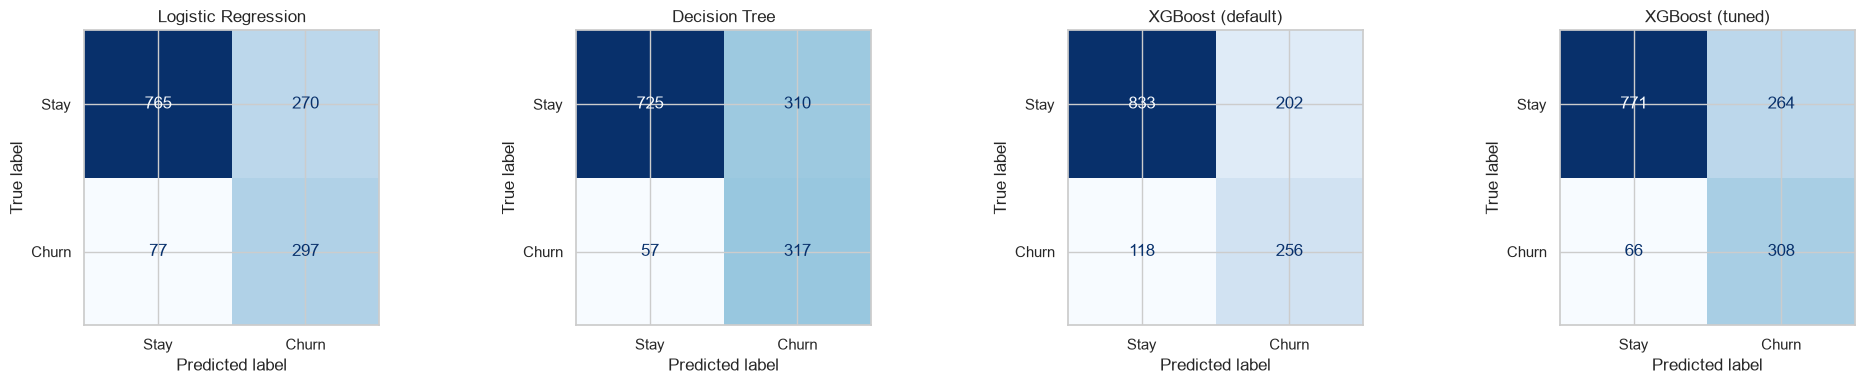

In [43]:
# Confusion Matrix

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, proba) in zip(axes, test_proba.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (proba >= 0.5).astype(int), display_labels=["Stay", "Churn"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

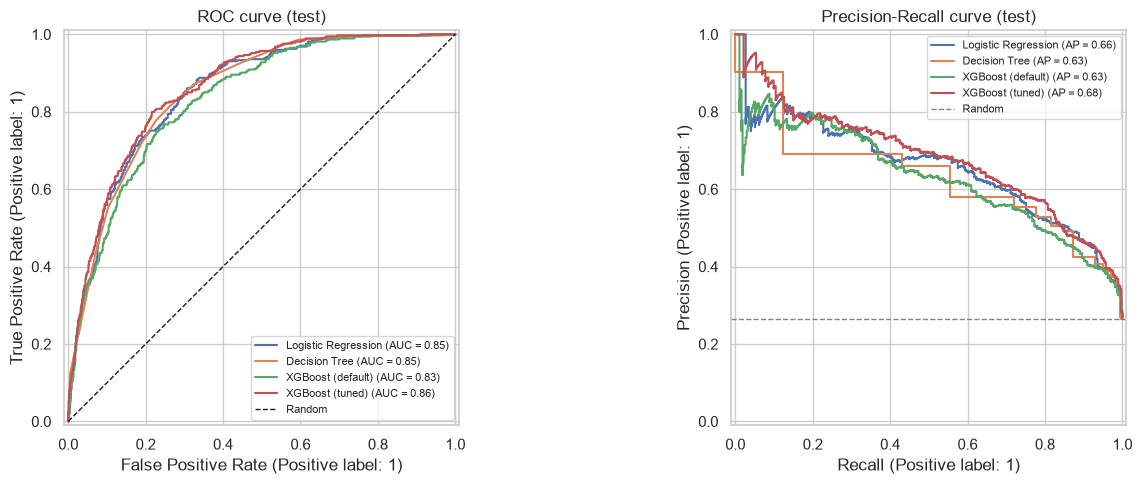

In [44]:
# ROC and Precision/Recall Curves

from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, proba in test_proba.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Random")
axes[0].set_title("ROC curve (test)")
axes[1].axhline(y_test.mean(), color="gray", linestyle="--", linewidth=1, label="Random")
axes[1].set_title("Precision-Recall curve (test)")
for ax in axes:
    ax.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

### Final evaluation: findings

- **Tuned XGBoost is the best model on unseen data:** PR-AUC 0.680, ROC-AUC 0.862
  and F1 0.651, confirming the cross-validation ranking.
- **In business terms** (374 churners in the test set): tuned XGBoost detects
  **308 churners (82.4%)** and misses 66. Compared with Logistic Regression
  (297 detected, 270 false alarms), it catches **11 more churners with 6 fewer
  false alarms** (264).
- **Default XGBoost is the most conservative:** fewest false alarms (202) but it
  misses 118 churners, almost twice as many as the tuned version.
- **The Decision Tree detects the most churners (317)** but raises the most false
  alarms (310): it labels broad groups as "at risk".
- **Test scores are slightly higher than cross-validation** (+0.01 to +0.04 PR-AUC).
  This is normal variation between samples; the model ranking is the same, which
  means the cross-validation estimates were reliable and there was no leakage.
- **About half of the alerts are false alarms** (precision ~0.54) at the default
  0.5 threshold. Whether that is acceptable depends on the cost of a retention
  action vs. the cost of losing a customer: that's what Step 12 decides.

### 12. Business-Cost Threshold

The 0.5 threshold is arbitrary. Here we choose it by **money saved**, using
each customer's own monthly charges:

| Outcome | Cost |
|---|---|
| Churner contacted (TP) | offer cost + revenue lost if the offer fails |
| Loyal customer contacted (FP) | offer cost |
| Churner missed (FN) | 12 months of revenue lost |
| Loyal customer not contacted (TN) | 0 |

**Savings** = cost of doing nothing (losing every churner) − cost with the model.

To avoid using the test set twice, the threshold is chosen with **out-of-fold
predictions on the training set** (`cross_val_predict`) and then applied once to
the test set.

In [45]:
# Business cost assumptions (illustrative)
OFFER_COST = 50              # cost of a retention action (discount, call), in $
REVENUE_MONTHS = 12          # months of revenue lost when a customer churns
OFFER_SUCCESS_RATE = 0.30    # share of contacted churners who stay thanks to the offer

def business_cost(y_true, proba, threshold, monthly_charges):
    """Total cost of contacting every customer with churn probability >= threshold."""
    y_true = np.asarray(y_true)
    contact = np.asarray(proba) >= threshold
    lost = np.asarray(monthly_charges) * REVENUE_MONTHS
    tp = contact & (y_true == 1)
    fp = contact & (y_true == 0)
    fn = ~contact & (y_true == 1)
    cost = (OFFER_COST * tp.sum() + ((1 - OFFER_SUCCESS_RATE) * lost[tp]).sum()
            + OFFER_COST * fp.sum()
            + lost[fn].sum())
    return cost, tp.sum(), fp.sum(), fn.sum()

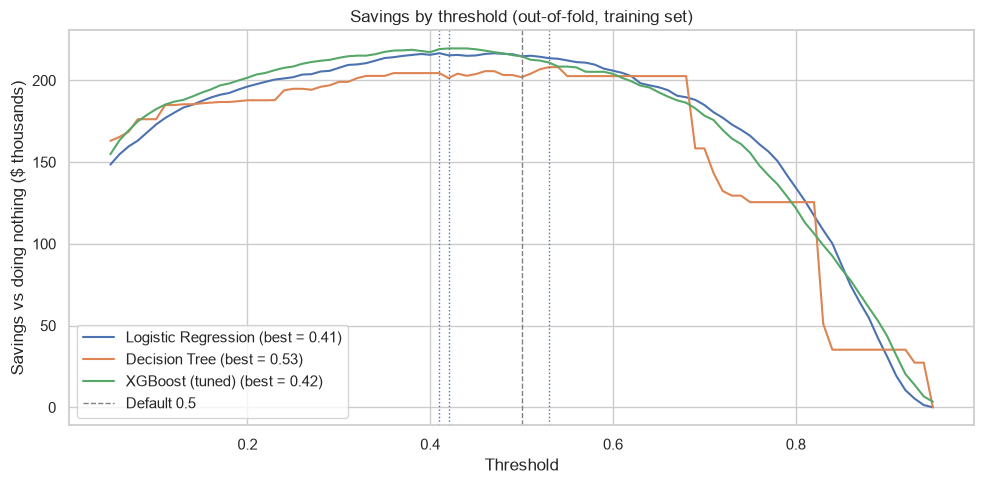

Logistic Regression    0.41
Decision Tree          0.53
XGBoost (tuned)        0.42
Name: cost-optimal threshold, dtype: float64

In [46]:
# Select the best threshold

from sklearn.model_selection import cross_val_predict

COST_MODELS = {"Logistic Regression": log_reg,
               "Decision Tree": decision_tree,
               "XGBoost (tuned)": xgb_tuned}
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.01), 2)

oof_proba = {name: cross_val_predict(model, X_train, y_train, cv=cv,
                                     method="predict_proba", n_jobs=-1)[:, 1]
             for name, model in COST_MODELS.items()}

do_nothing_train = (X_train.loc[y_train == 1, "MonthlyCharges"] * REVENUE_MONTHS).sum()

savings_curves = {
    name: pd.Series([do_nothing_train - business_cost(y_train, proba, t, X_train["MonthlyCharges"])[0]
                     for t in THRESHOLDS], index=THRESHOLDS)
    for name, proba in oof_proba.items()
}
best_thresholds = {name: curve.idxmax() for name, curve in savings_curves.items()}

fig, ax = plt.subplots(figsize=(10, 5))
for name, curve in savings_curves.items():
    ax.plot(curve.index, curve / 1000, label=f"{name} (best = {best_thresholds[name]:.2f})")
    ax.axvline(best_thresholds[name], linestyle=":", linewidth=1)
ax.axvline(0.5, color="gray", linestyle="--", linewidth=1, label="Default 0.5")
ax.set_xlabel("Threshold")
ax.set_ylabel("Savings vs doing nothing ($ thousands)")
ax.set_title("Savings by threshold (out-of-fold, training set)")
ax.legend()
plt.tight_layout()
plt.show()

pd.Series(best_thresholds, name="cost-optimal threshold")

In [47]:
# Apply to Test

do_nothing_test = (X_test.loc[y_test == 1, "MonthlyCharges"] * REVENUE_MONTHS).sum()

rows = []
for name in COST_MODELS:
    for label, thr in [("default", 0.5), ("cost-optimal", best_thresholds[name])]:
        cost, tp, fp, fn = business_cost(y_test, test_proba[name], thr, X_test["MonthlyCharges"])
        rows.append({"model": name, "threshold": label, "value": thr,
                     "detected": tp, "missed": fn, "false alarms": fp, "contacted": tp + fp,
                     "savings ($)": round(do_nothing_test - cost),
                     "savings (%)": round((do_nothing_test - cost) / do_nothing_test * 100, 1)})

contact_all_cost = business_cost(y_test, np.ones(len(y_test)), 0.5, X_test["MonthlyCharges"])[0]
print(f"Cost of doing nothing (test): ${do_nothing_test:,.0f}")
print(f"Savings if we contact everyone: ${do_nothing_test - contact_all_cost:,.0f}")
pd.DataFrame(rows)

Cost of doing nothing (test): $336,272
Savings if we contact everyone: $30,432


,model,threshold,value,detected,missed,false alarms,contacted,savings ($),savings (%)
0,Logistic Regression,default,0.50,297,77,270,567,54893,16.3
1,Logistic Regression,cost-optimal,0.41,326,48,341,667,56304,16.7
2,Decision Tree,default,0.50,317,57,310,627,54451,16.2
3,Decision Tree,cost-optimal,0.53,269,105,196,465,53012,15.8
4,XGBoost (tuned),default,0.50,308,66,264,572,56250,16.7
5,XGBoost (tuned),cost-optimal,0.42,320,54,337,657,54327,16.2


In [48]:
sensitivity = []
for rate in [0.10, 0.20, 0.30, 0.50]:
    lost = X_train["MonthlyCharges"].to_numpy() * REVENUE_MONTHS
    y_arr, p = y_train.to_numpy(), oof_proba["XGBoost (tuned)"]
    savings = []
    for t in THRESHOLDS:
        c = p >= t
        tp, fp, fn = c & (y_arr == 1), c & (y_arr == 0), ~c & (y_arr == 1)
        cost = (OFFER_COST * (tp.sum() + fp.sum()) + ((1 - rate) * lost[tp]).sum() + lost[fn].sum())
        savings.append(do_nothing_train - cost)
    savings = pd.Series(savings, index=THRESHOLDS)
    sensitivity.append({"offer success rate": rate, "best threshold": savings.idxmax(),
                        "savings (%)": round(savings.max() / do_nothing_train * 100, 1)})
pd.DataFrame(sensitivity)

,offer success rate,best threshold,savings (%)
0,0.1,0.76,1.2
1,0.2,0.59,7.9
2,0.3,0.42,16.5
3,0.5,0.27,34.6


### Business-cost threshold: findings

- **Using a model nearly doubles the value of a retention campaign:** contacting
  everyone saves ~$30K on the test set, while any of the three models saves
  ~$53–56K (about 16% of the $336K of revenue at risk).
- **The savings curve is flat around the optimum:** thresholds between ~0.35 and
  0.50 save almost the same. On the test set, tuned XGBoost saves $56,250 at 0.5
  vs $54,327 at its cost-optimal 0.42: a ~$2K difference that is noise, not signal.
  With these assumptions, the exact threshold matters little.
- **All three models end up within ~$3K of each other** ($53,012–$56,304).
  In money terms, the choice of model matters much less than the business assumptions.
- **The offer success rate is the real lever:** if only 10% of contacted churners
  stay, the campaign barely pays off (1.2% savings) and only the riskiest
  customers should be contacted (threshold 0.76). At 50%, savings reach 34.6% and
  it pays to contact many more customers (threshold 0.27).
- **Decision:** we keep tuned XGBoost with the threshold chosen on the training
  set (0.42). Switching to 0.5 after seeing the test results would mean using the
  test set to make a decision. The threshold is reported as a **business-adjustable
  parameter**, to be recalibrated once the real offer cost and success rate are
  known (for example, from an A/B test).

### 13. Error Analysis

Where does the final model (tuned XGBoost, cost-optimal threshold) fail, and why?
We compare the profile of the four outcomes on the test set:

- **Detected churner (TP):** churned and was flagged.
- **Missed churner (FN):** churned but was not flagged. These are the costliest errors.
- **False alarm (FP):** flagged but stayed.
- **Correct stay (TN):** stayed and was not flagged.

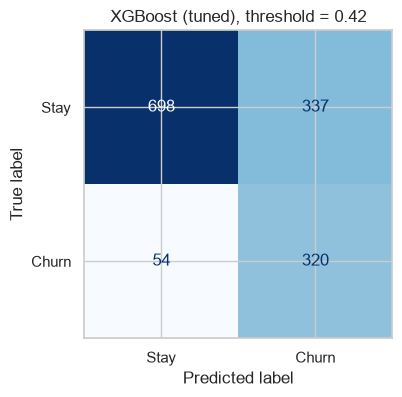

In [49]:
from sklearn.metrics import ConfusionMatrixDisplay

BEST_THRESHOLD = best_thresholds["XGBoost (tuned)"]

# Label every test customer with its outcome (needed for the profiles below)
errors = X_test.copy()
errors["Churn"] = y_test.to_numpy()
errors["proba"] = test_proba["XGBoost (tuned)"]
errors["predicted"] = (errors["proba"] >= BEST_THRESHOLD).astype(int)
errors["outcome"] = np.select(
    [(errors["Churn"] == 1) & (errors["predicted"] == 1),
     (errors["Churn"] == 1) & (errors["predicted"] == 0),
     (errors["Churn"] == 0) & (errors["predicted"] == 1)],
    ["Detected churner (TP)", "Missed churner (FN)", "False alarm (FP)"],
    default="Correct stay (TN)",
)
# Internet customers with no protection/support service at all
errors["no_protection"] = ((errors["InternetService"] != "No")
                           & ((errors[PROTECTION_COLS] == "Yes").sum(axis=1) == 0)) * 100

# Confusion matrix at the cost-optimal threshold
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    errors["Churn"], errors["predicted"], display_labels=["Stay", "Churn"],
    cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"XGBoost (tuned), threshold = {BEST_THRESHOLD:.2f}")
plt.show()

In [50]:
# Result Breakdown

order = ["Detected churner (TP)", "Missed churner (FN)", "False alarm (FP)", "Correct stay (TN)"]

profile = errors.groupby("outcome").agg(
    customers=("Churn", "size"),
    avg_probability=("proba", "mean"),
    median_tenure=("tenure", "median"),
    median_monthly_charge=("MonthlyCharges", "median"),
    month_to_month_pct=("Contract", lambda s: (s == "Month-to-month").mean() * 100),
    fiber_optic_pct=("InternetService", lambda s: (s == "Fiber optic").mean() * 100),
    no_protection_pct=("no_protection", "mean"),
    electronic_check_pct=("PaymentMethod", lambda s: (s == "Electronic check").mean() * 100),
).loc[order]

profile.round({"avg_probability": 2, "median_monthly_charge": 1, "month_to_month_pct": 1,
               "fiber_optic_pct": 1, "no_protection_pct": 1, "electronic_check_pct": 1})

,customers,avg_probability,median_tenure,median_monthly_charge,month_to_month_pct,fiber_optic_pct,no_protection_pct,electronic_check_pct
outcome,,,,,,,,
Detected churner (TP),320,0.76,7.0,80.0,96.9,75.3,46.2,64.4
Missed churner (FN),54,0.28,39.0,67.6,44.4,35.2,0.0,18.5
False alarm (FP),337,0.64,16.0,80.0,88.7,65.0,30.3,50.4
Correct stay (TN),698,0.14,48.0,54.3,19.2,19.1,2.9,13.0


In [51]:
# Analysis of Undetected Churn Cases
missed = errors[errors["outcome"] == "Missed churner (FN)"]

display(missed["Contract"].value_counts().rename("missed churners by contract"))
display(missed["InternetService"].value_counts().rename("missed churners by internet"))
pd.cut(missed["proba"], bins=[0, 0.1, 0.2, 0.3, BEST_THRESHOLD]).value_counts().sort_index()


Contract
Month-to-month    24
One year          22
Two year           8
Name: missed churners by contract, dtype: int64

InternetService
DSL            29
Fiber optic    19
No              6
Name: missed churners by internet, dtype: int64

proba
(0.0, 0.1]      3
(0.1, 0.2]     11
(0.2, 0.3]     12
(0.3, 0.42]    28
Name: count, dtype: int64

### Error analysis: findings

- **Missed churners look like loyal customers.** Median tenure of 39 months
  (vs 7 for detected churners), 55.6% on one- or two-year contracts (30 of 54),
  mostly DSL (29 of 54), and none of the internet customers among them lacked
  protection services. They have none of the risk factors the model learned,
  so they are **hard to predict with this data**: their reasons for leaving
  (a competitor's offer, moving, a service incident) are not in the dataset.
- **About half of them were close to the threshold:** 28 of 54 had a probability
  between 0.30 and 0.42. A lower threshold would catch some of them, at the cost
  of more false alarms (Step 12).
- **False alarms look like churners.** 88.7% are month-to-month, median tenure is
  16 months, 65.0% have fiber. They match the risk profile but stayed, at least
  for now. They are not wasted contacts: they are **at-risk customers**, and a
  retention offer may still be reasonable for them.
- **The model is good at finding the classic churner:** new (median tenure 7 months),
  month-to-month (96.9% of detected churners), fiber (75.3%) and electronic check
  (64.4%). It is weak on "unexpected" churners with a loyal profile.
- **To improve it, the model needs new information, not more tuning:** customer
  service calls, complaints, network incidents, competitor pricing or usage trends.

### 14. Business Conclusions

#### Results at a glance

| | Value |
|---|---|
| Customers / churners | 7,043 / 1,869 (26.5%) |
| Final model | Tuned XGBoost (`max_depth=2`, 476 trees) |
| Test PR-AUC / ROC-AUC | 0.680 / 0.862 (random PR-AUC: 0.265) |
| Threshold | 0.42 (chosen by business cost on the training set) |
| Churners detected (test) | 320 of 374 (85.6%) |
| Customers contacted (test) | 657, of which 48.7% actually churn |
| Savings vs doing nothing (test) | $54,327 of $336,272 at risk (16.2%) |
| Savings if we contact everyone | $30,432 |

#### Who churns

Churn is concentrated, not spread out. The typical churner is a **new,
month-to-month customer with fiber optic and no protection services, paying
by electronic check**:
- 88.6% of churners are month-to-month; 54.8% are month-to-month customers in
  their **first year**.
- Fiber without protection services churns at 63.6%; with all four protection
  services, churn drops to 8.4%.
- Electronic check users churn at 45.3% and account for 57.3% of churners.

#### Recommended actions

1. **Lock in new customers early.** Offer month-to-month customers an incentive
   to move to a one-year contract within their first months. This group holds
   more than half of all churners, and brand-new fiber customers leave almost
   immediately (85.6% churn in the riskiest Decision Tree rule).
2. **Bundle protection services with fiber.** Offer fiber customers without
   add-ons a free trial of tech support or online security. Churn falls steadily
   with every protection service added, for both fiber and DSL.
3. **Move electronic check payers to automatic payment** (bank transfer or credit
   card), for example with a small billing discount.
4. **Use the model to prioritize, and measure the offer.** Score customers
   monthly and contact those above the threshold. Keep a random control group:
   the offer's real success rate is the factor that most changes the campaign's
   value (from 1.2% savings at 10% success to 34.6% at 50%), and the threshold
   should be recalibrated once it is known.

#### What we cannot confirm

- **Association is not causation.** Customers with protection services or long
  contracts churn less, but they may simply be more committed customers. Only an
  experiment (A/B test) can show whether offering these services *causes* lower churn.
- **The cost figures are illustrative.** The $50 offer cost, the 12 months of lost
  revenue and the 30% success rate are assumptions, not company data.
- **About half of the contacted customers will not churn** (precision 48.7%). The
  retention action must be cheap enough to justify contacting them.
- **Some churners can't be predicted with this data.** The 54 missed churners
  have a loyal profile; their reasons for leaving are not in the dataset.
- **The data is a static snapshot** (IBM sample dataset), with no dates, usage,
  complaints or customer service history. A production model would need them,
  and would need to be monitored and retrained over time.

### 15. Save the Final Pipeline

The full pipeline (feature engineering + preprocessing + tuned XGBoost) is saved
with `joblib`, so raw customer data can be passed in directly. The threshold and
the context needed to use it are saved in a JSON file.

In [52]:
import joblib
import json
import sklearn
import xgboost
from datetime import date

PIPELINE_PATH = "customersretention_pipeline.joblib"
THRESHOLD_PATH = "customersretention_threshold.json"

final_model = xgb_tuned            # trained on the full training set in Step 11
joblib.dump(final_model, PIPELINE_PATH)

final_pred = (test_proba["XGBoost (tuned)"] >= BEST_THRESHOLD).astype(int)
metadata = {
    "model": "XGBoost (tuned)",
    "threshold": float(BEST_THRESHOLD),
    "input_features": list(X_train.columns),
    "cost_assumptions": {"offer_cost": OFFER_COST,
                         "revenue_months": REVENUE_MONTHS,
                         "offer_success_rate": OFFER_SUCCESS_RATE},
    "test_metrics": {
        "pr_auc": round(float(average_precision_score(y_test, test_proba["XGBoost (tuned)"])), 3),
        "roc_auc": round(float(roc_auc_score(y_test, test_proba["XGBoost (tuned)"])), 3),
        "recall": round(float(recall_score(y_test, final_pred)), 3),
        "precision": round(float(precision_score(y_test, final_pred)), 3),
    },
    "versions": {"scikit-learn": sklearn.__version__,
                 "xgboost": xgboost.__version__,
                 "pandas": pd.__version__},
    "created": date.today().isoformat(),
}
with open(THRESHOLD_PATH, "w") as f:
    json.dump(metadata, f, indent=2)

print(f"Saved {PIPELINE_PATH} and {THRESHOLD_PATH}")

Saved customersretention_pipeline.joblib and customersretention_threshold.json


In [53]:
loaded_model = joblib.load(PIPELINE_PATH)
with open(THRESHOLD_PATH) as f:
    config = json.load(f)

reloaded_proba = loaded_model.predict_proba(X_test)[:, 1]
print("Same predictions as before saving:",
      np.allclose(reloaded_proba, test_proba["XGBoost (tuned)"]))

# Example: score one customer with raw data
customer = X_test.iloc[[0]]
proba = loaded_model.predict_proba(customer)[0, 1]
print(f"Churn probability: {proba:.3f} -> contact: {proba >= config['threshold']}")

Same predictions as before saving: True
Churn probability: 0.706 -> contact: True
